# Merged code

Merge two code blocks through an ancilla system to measure a logical XX operator.

In [1]:
import numpy as np
import galois
import networkx as nx
import matplotlib.pyplot as plt
from sympy import symbols, Poly

from core.primitives import Check
from core.CSS import LPCode, LinearCode, HGPCode
from core.codes import SurfaceCode, EmptyPatch, LPCodePatch, HGPCodePatch, AncillaGraph
from surgery.surgery import (ConePatch, MergedCodeWithGraph, Homomorphism, TrivialHomomorphism,
                             HighRateSurgeryPatch, MergedHighRateSurgeryPatch)
from viz.layout import visualize

## Surface code + surface code

XX-cone-surface CSS code parameters: dx=7, dz=14, k=1


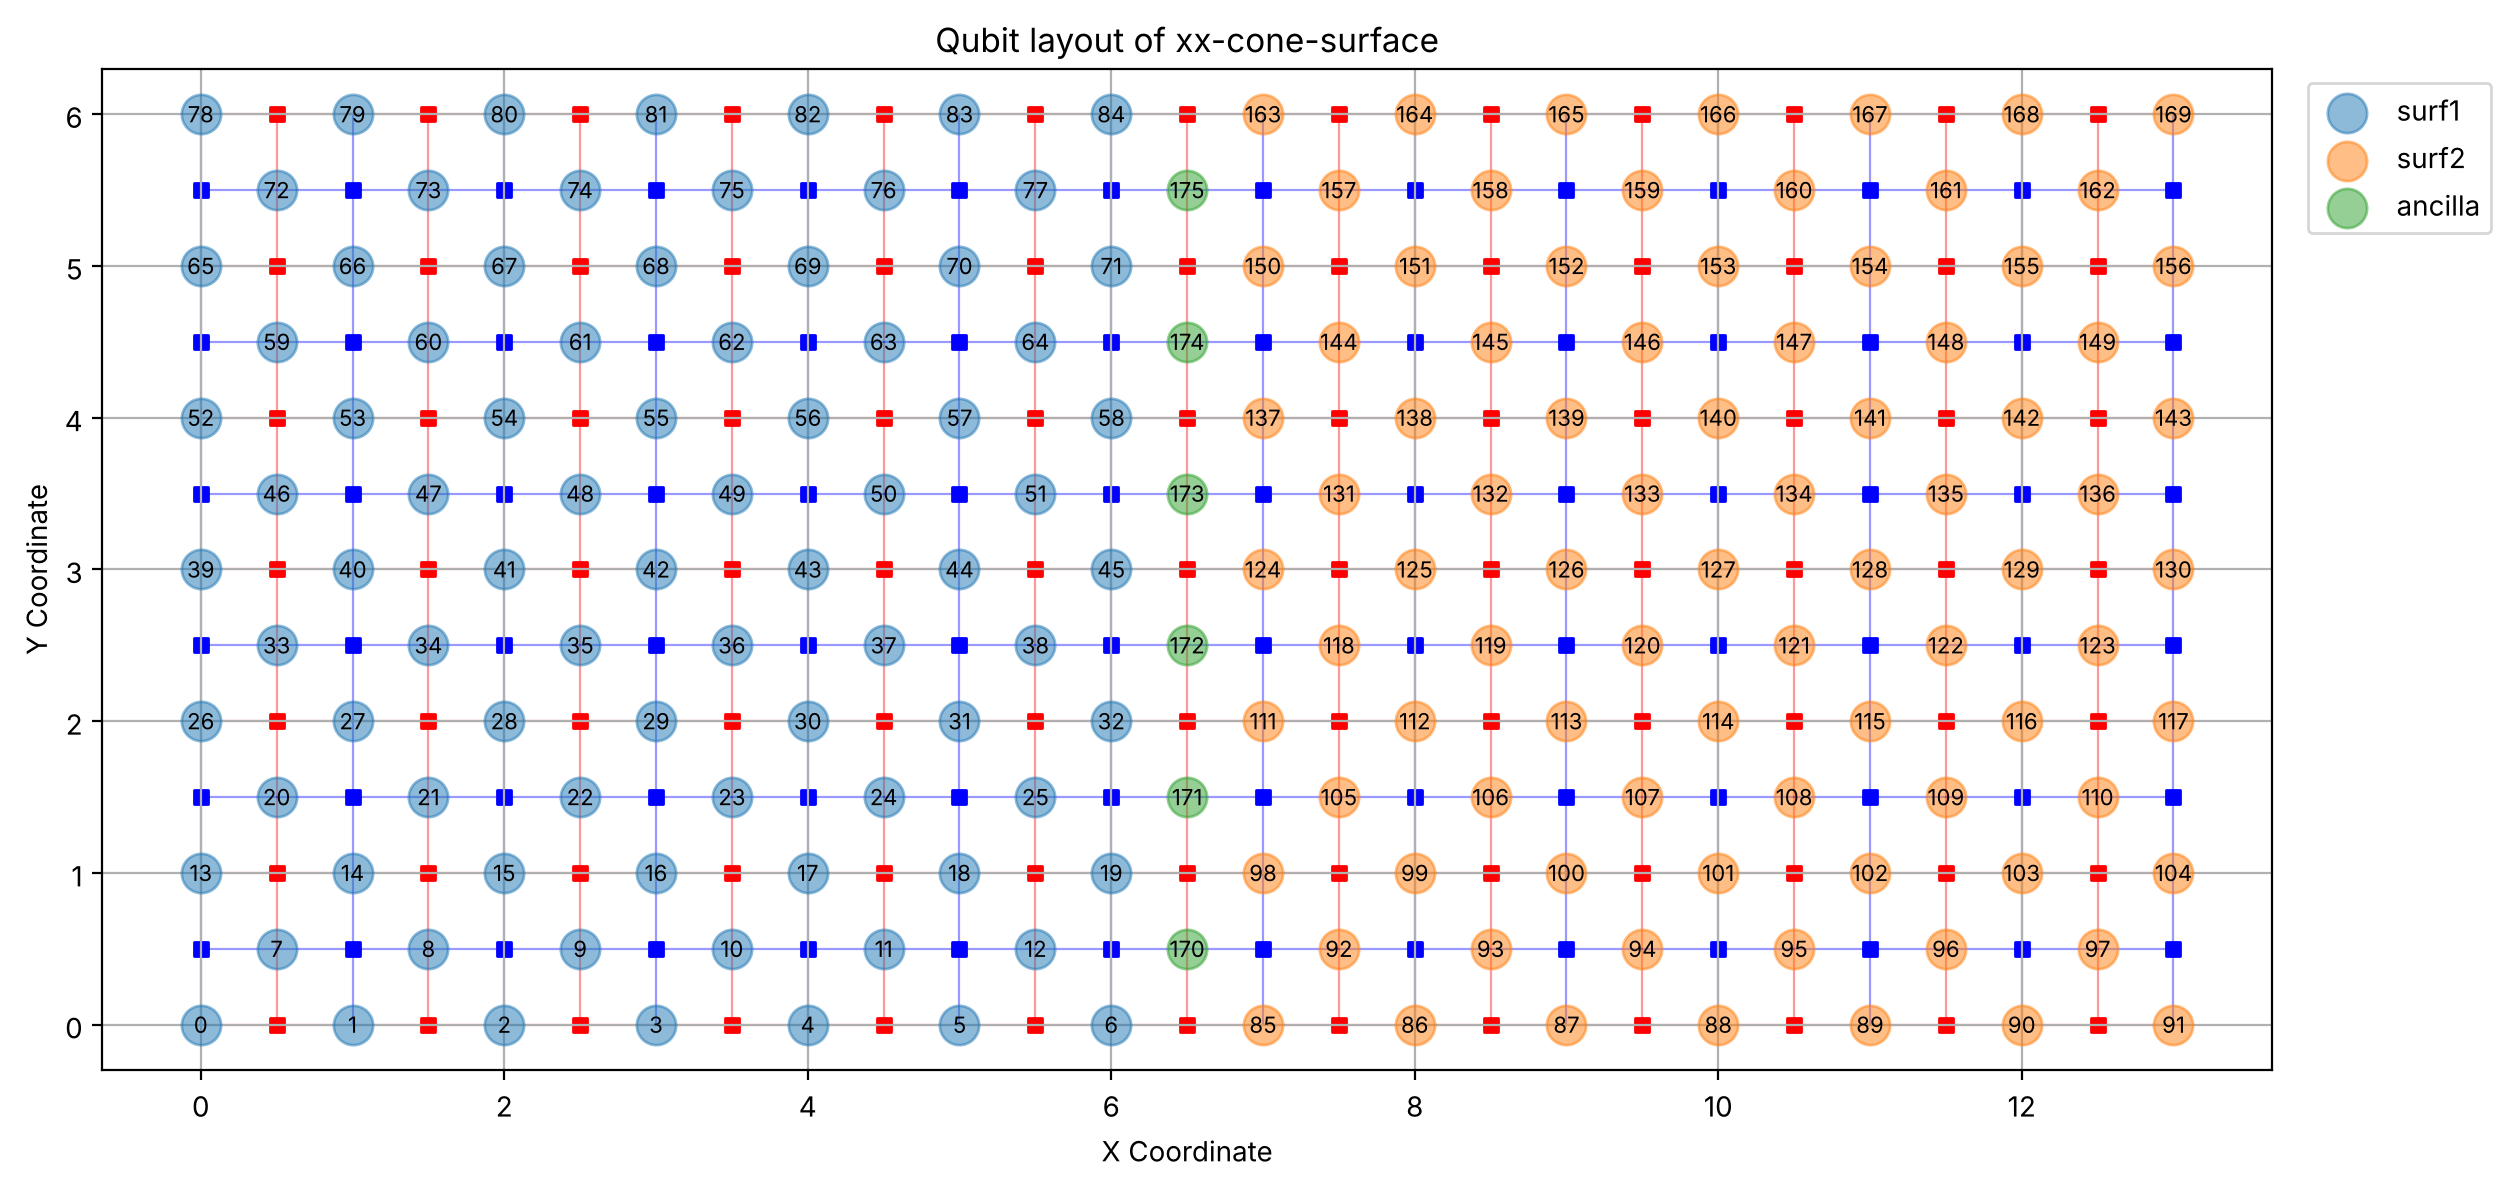

In [2]:
d = 7
C1 = SurfaceCode(d, patch_name="surf1", offset=(0.0,0.0))
C2 = SurfaceCode(d, patch_name="surf2", offset=(d,0.0))
A  = EmptyPatch(patch_name="ancilla", offset=(d-0.5,0.5))

for i in range(d-1):
    A.add_qubit(0, i)
A.add_check([A.data_qubits()[0]], "X")
for i in range(1,d-1):
    A.add_check([A.data_qubits()[i-1], A.data_qubits()[i]], "X")
A.add_check([A.data_qubits()[d-2]], "X")
# ancilla X check coordinates: between the two patch boundaries (for visualization)
A.set_check2coord({chk: (0, i-0.5) for i, chk in enumerate(A.x_checks())})

f0 = [Check.get_empty_check()]*len(C1.z_checks()+C2.z_checks())
for i in range(d-1):
    f0[i*d + (d-1)] = Check(frozenset([A.data_qubits()[i]]), "Z")
for i in range(d-1):
    f0[len(C1.z_checks()) + i*d] = Check(frozenset([A.data_qubits()[i]]), "Z")

f1t = [Check.get_empty_check()]*len(A.x_checks())
for i in range(d):
    f1t[i] = Check(frozenset([C1._get_qubit_from_coord(d-1,i), C2._get_qubit_from_coord(0,i)]), "X")

xx = ConePatch([C1, C2], A, f1t, f0, name="xx-cone-surface")
# print("XX-cone-surface X checks:")
# for chk in xx.x_checks():
#     print([q.local_coord for q in chk.qubits], chk.pauli, chk.label)
# print("XX-cone-surface Z checks:")
# for chk in xx.z_checks():
#     print([q.local_coord for q in chk.qubits], chk.pauli, chk.label)
# for q in xx.data_qubits():
#     print(q, xx.local_coord(q), xx.get_idx(q))
css = xx.make_css()
dx, dz = css.get_distance()
k = css.get_k()
print(f"XX-cone-surface CSS code parameters: dx={dx}, dz={dz}, k={k}")

visualize(xx)
plt.show()

## LP code + LP code

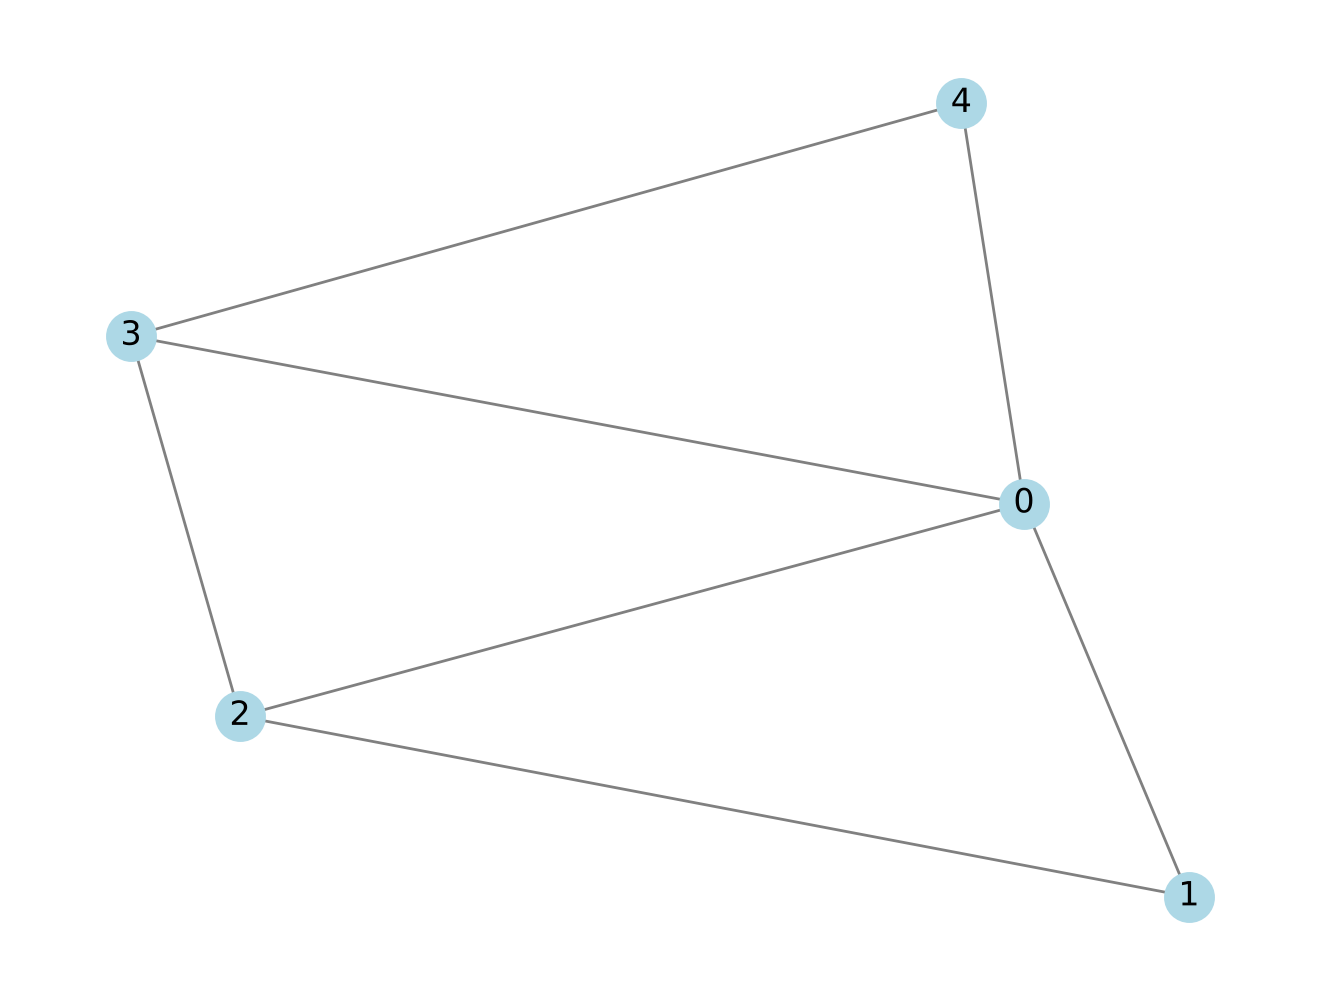

n=71, k=15


Distance: dx=3, dz=3


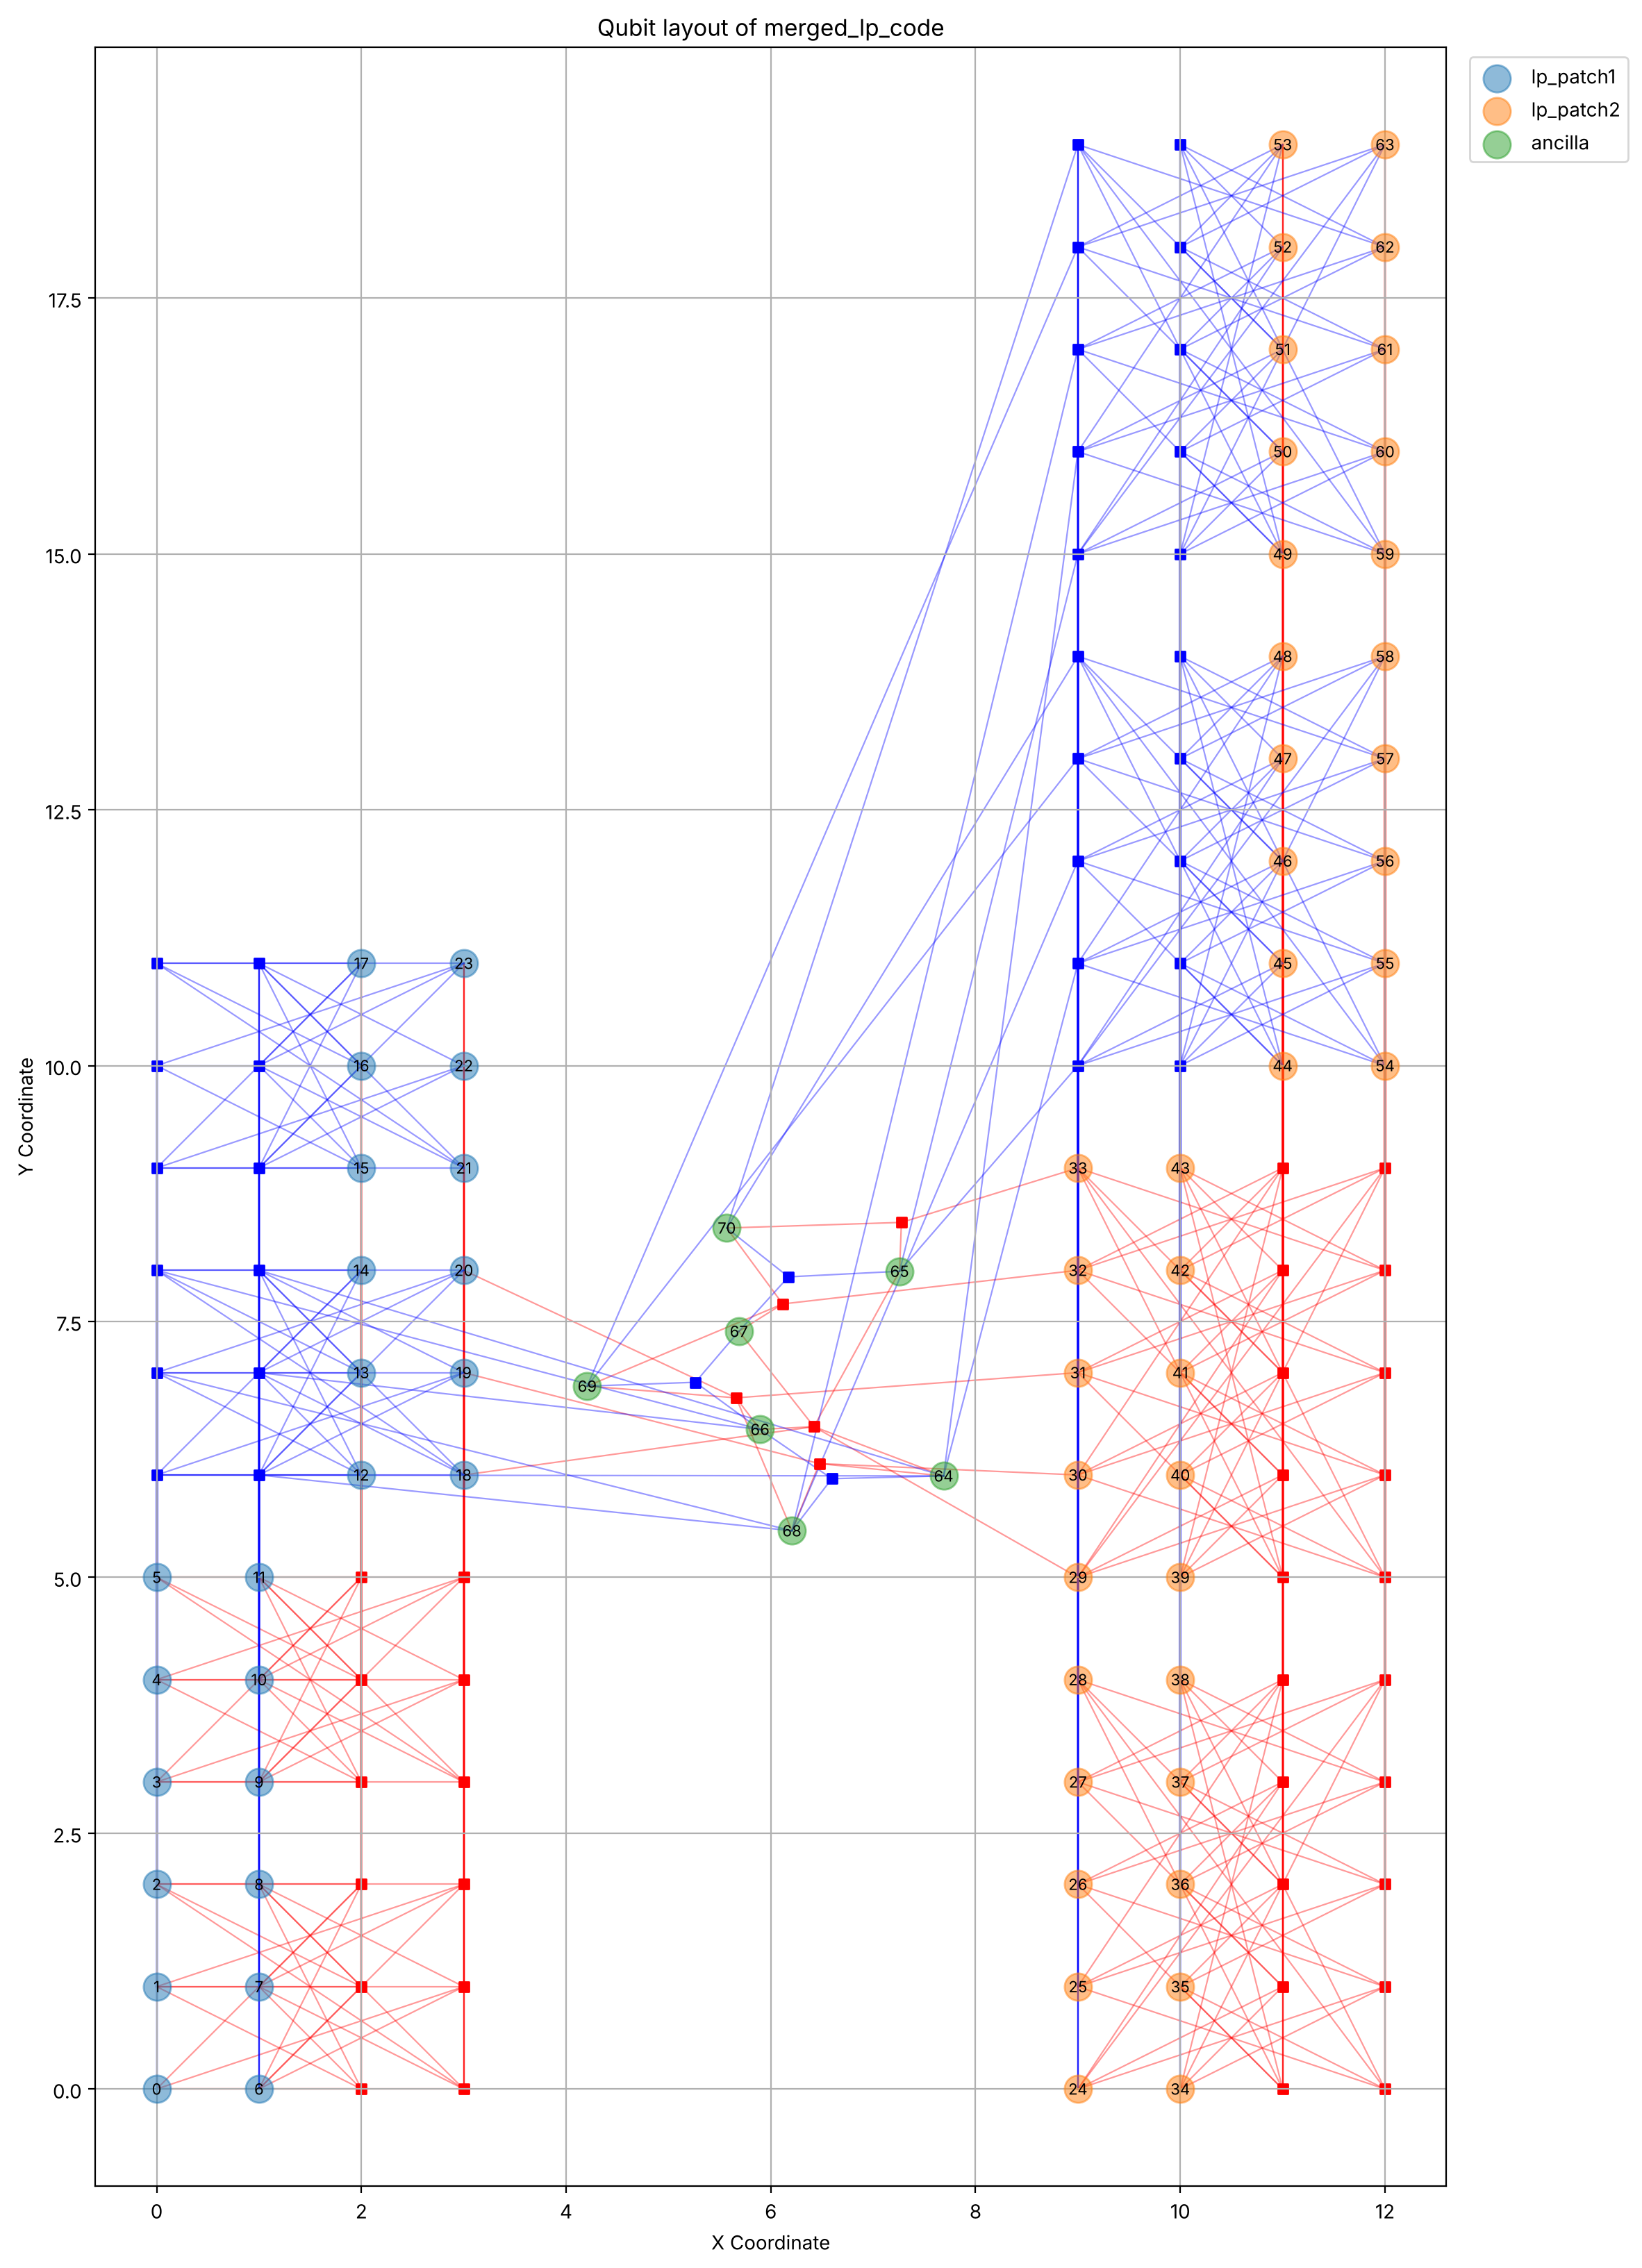

In [3]:
"""
[[24,8,3]] LP code
"""
x = symbols('x')
ring = Poly(x**3+1, x, modulus=2)
Ha = [[Poly(1+x**2,x, modulus=2),Poly(x+x**2,x, modulus=2)],
        [Poly(1+x,x, modulus=2),Poly(x+x**2,x, modulus=2)]]
Hb = [[Poly(1+x**2,x, modulus=2),Poly(x+x**2,x, modulus=2)],
        [Poly(1+x,x, modulus=2),Poly(1+x,x, modulus=2)]]
lp1 = LPCode(Ha=Ha, Hb=Hb, R=ring)  # [[24,8,3]] code

op = [[0]*24 for _ in range(8)]
for i in range(8):
    op[i][3*i:3*i+3] = [1]*3
lx = op
lz = op
lp1.set_logical_representatives(lx, lz)

lp_patch1 = LPCodePatch(css=lp1, patch_name="lp_patch1", offset=(0.0,0.0))

"""
[[40,8,5]] LP code
"""
x = symbols('x')
ring = Poly(x**5+1, x, modulus=2)

Ha = [[Poly(x+x**3,x, modulus=2),Poly(x+x**4,x, modulus=2)],
        [Poly(x+x**4,x, modulus=2),Poly(x+x**4,x, modulus=2)]]
Hb = [[Poly(1+x,x, modulus=2),Poly(x**3+x**4,x, modulus=2)],
        [Poly(1+x**4,x, modulus=2),Poly(1+x**4,x, modulus=2)]]
lp2 = LPCode(Ha=Ha, Hb=Hb, R=ring)  # [[40,8,5]] code
op = [[0]*40 for _ in range(8)]
for i in range(8):
    op[i][5*i:5*i+5] = [1]*5
lx = op
lz = op
lp2.set_logical_representatives(lx, lz)

lp_patch2 = LPCodePatch(css=lp2, patch_name="lp_patch2", offset=(0.0,0.0))

"""
Ancillary graph
"""
G = nx.Graph()
G.add_edges_from([(0,1),(1,2),(2,3),(3,4),(4,0),(0,2),(0,3)])
anc = AncillaGraph(G, patch_name="ancilla", type="X", offset=(0.0,0.0))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', edge_color='gray')
plt.show()

"""
Merge
"""
X1 = lp_patch1.get_logical_representative("X", 6)
X2 = lp_patch2.get_logical_representative("X", 1)

anc._offset = (4.0, 5.0)  # move the ancilla graph between the two LP patches
anc.scale = (4.0, 4.0)  # scale up the ancilla graph
lp_patch2._offset = (9.0, 0.0)  # move lp_patch2 to the right
merged_code = MergedCodeWithGraph(lp_patch1, lp_patch2, anc, X1=X1, X2=X2, name="merged_lp_code")
merged_code.make_css()
css = merged_code.css

"""
Set logicals
"""
# Measure X_7 of lp1 times X_2 of lp2
# 15 logicals in this order: X_1,...,X_8 of lp1, then X_1,X_3,...,X_8 of lp2
for idx in range(8):
    support = galois.GF(2)([0]*css.n)
    op = lp_patch1.get_logical_representative("X", idx)
    for qubit in op:
        support[merged_code.get_idx(qubit)] = 1
    merged_code.css.set_logical_representative("X", idx, support)
for i, idx in enumerate([0,2,3,4,5,6,7]):
    support = galois.GF(2)([0]*css.n)
    op = lp_patch2.get_logical_representative("X", idx)
    for qubit in op:
        support[merged_code.get_idx(qubit)] = 1
    merged_code.css.set_logical_representative("X", i+8, support)

# Logical Z
for idx in [0,1,2,3,4,5,7]:
    support = galois.GF(2)([0]*css.n)
    op = lp_patch1.get_logical_representative("Z", idx)
    for qubit in op:
        support[merged_code.get_idx(qubit)] = 1
    merged_code.css.set_logical_representative("Z", idx, support)
for i, idx in enumerate([0,2,3,4,5,6,7]):
    support = galois.GF(2)([0]*css.n)
    op = lp_patch2.get_logical_representative("Z", idx)
    for qubit in op:
        support[merged_code.get_idx(qubit)] = 1
    merged_code.css.set_logical_representative("Z", i+8, support)
merged_code.css.set_missing_logicals()

print(f"n={css.n}, k={css.k}")
dx, dz = css.get_distance()
print(f"Distance: dx={dx}, dz={dz}")

visualize(merged_code)
plt.show()

## High-rate surgery


measured logicals: L1+L2 , L3


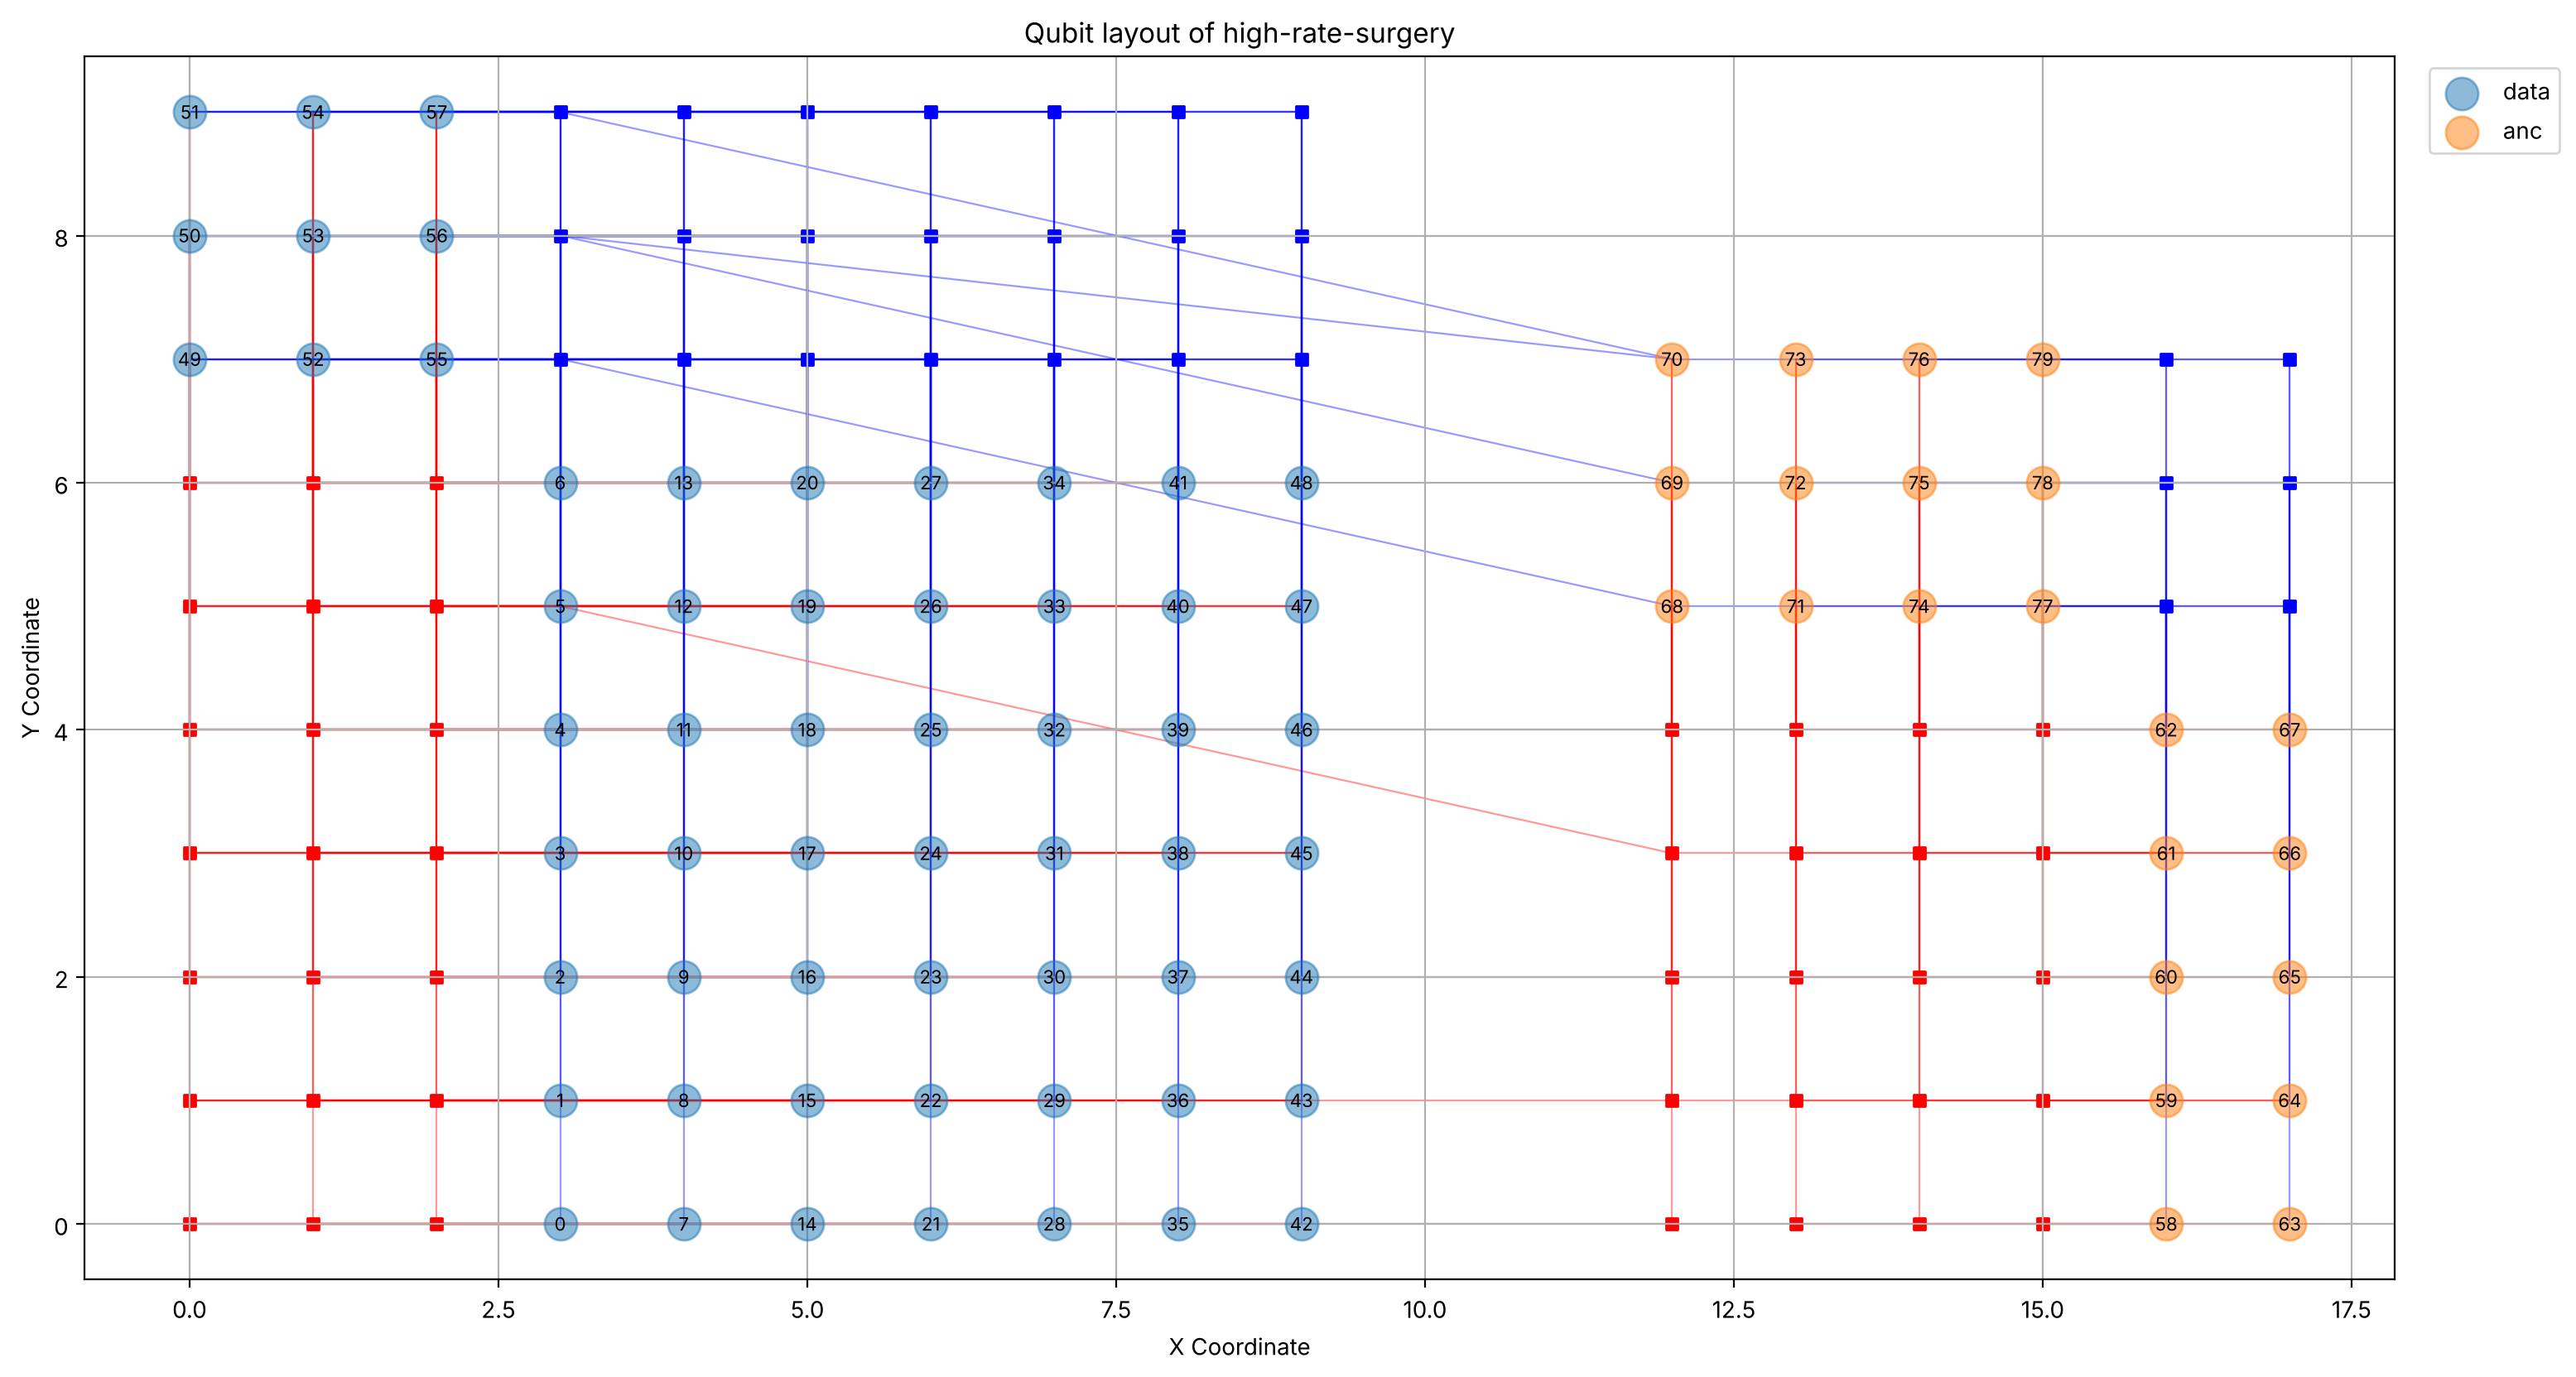

In [4]:
# homomorphism test
# Cb factors of the ancilla and the data. gamma: Cb_A -> Cb_C
Cb_A = LinearCode.from_generator([[1, 1, 1, 0, 0],
                                  [0, 0, 1, 1, 1]])         # ancilla base [5,2,3]
Cb_C = LinearCode([[1, 0, 1, 0, 1, 0, 1],                   # data base Hamming [7,4,3]
                   [0, 1, 1, 0, 0, 1, 1],
                   [0, 0, 0, 1, 1, 1, 1]])

# Cb_A.report("Cb_A (ancilla)")
# Cb_C.report("Cb_C (data, Hamming)")

ltol = np.array([[1, 0],     # L1(Cb_A) -> L1(Cb_C) + L2(Cb_C)
                 [1, 0],
                 [0, 1],     # L2(Cb_A) -> L3(Cb_C)
                 [0, 0]])

h = Homomorphism(Cb_A, Cb_C, ltol)      # ctol is searched automatically, gamma0 is computed too
# h.report()

# ---- high-rate surgery -------------------------------------------------
# data = standard HGP(Hamming, Hamming) = [[58,16]]
#   Ca_C = LinearCode(Hb_C^T) gives the standard HGP.
# ancilla = HGP([4,2], [5,2,3]) -> 2 columns
# h only on column 0 (ancilla) -> column 0 (data), the rest are trivial
Ca_C = LinearCode(np.asarray(Cb_C.H, dtype=int).T)
Ca_A = LinearCode([[1, 1, 0, 0],
                   [0, 0, 1, 1]])

C = HGPCodePatch(HGPCode(Ca_C, Cb_C), patch_name="data")
A = HGPCodePatch(HGPCode(Ca_A, Cb_A), patch_name="anc")
A._offset = (C.css.na + C.css.ra + 2, 0.0)

triv = TrivialHomomorphism(Cb_A, Cb_C)
S = HighRateSurgeryPatch(C, A, [(0, 0, h),        # only this column is measured
                                (1, 1, triv)])    # the rest measure nothing
# S.report()

# Check which logicals are measured (pair X-logicals with Z-logicals)
cssC = C.css
Lz = np.array([np.asarray(v, dtype=int) for v in cssC.logical_z_repr]).reshape(cssC.k, cssC.n)
coef = np.asarray(S.measured_operators() @ Lz.T, dtype=int) % 2
R = np.asarray(cssC.F(coef).row_reduce(), dtype=int)
R = R[R.any(axis=1)]
print("\nmeasured logicals:",
      " , ".join("+".join(f"L{i+1}" for i in np.nonzero(r)[0]) for r in R))

S.init_logical_representatives()

# print("X logical")
# for i in range(S.css.k):
#     print(f"X_{i+1}: {S.get_logical_representative('X', i)}")
# print("Z logical")
# for i in range(S.css.k):
#     print(f"Z_{i+1}: {S.get_logical_representative('Z', i)}")
# print(S.x_checks())

visualize(S)
plt.show()

## Merged high-rate surgery


measured logicals: L1+L2+M1+M2 , L3+M3


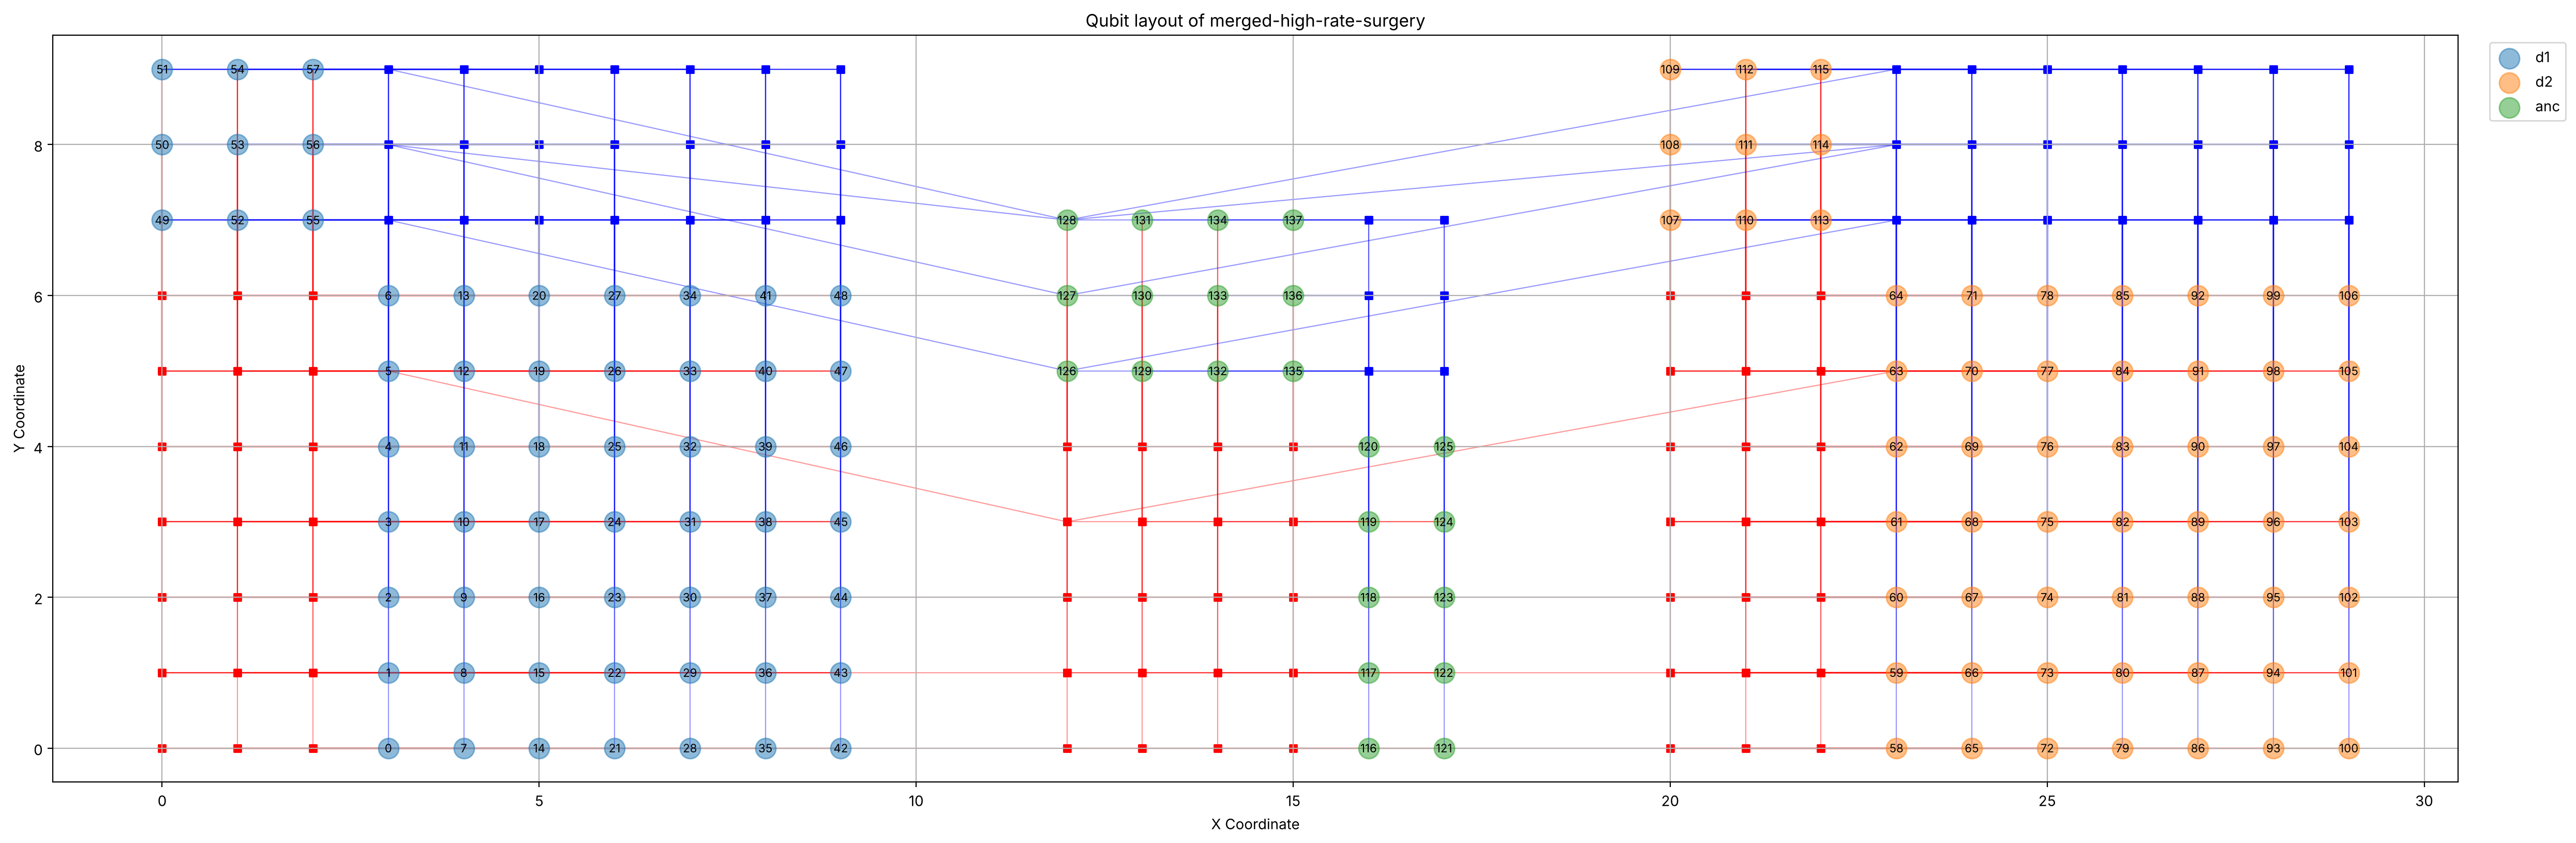

In [5]:
# Two-block version. Merge C1 and C2 through ancilla A to measure L^(1)·L^(2).
Cb_A = LinearCode.from_generator([[1, 1, 1, 0, 0],
                                  [0, 0, 1, 1, 1]])         # ancilla base [5,2,3]
Cb_C = LinearCode([[1, 0, 1, 0, 1, 0, 1],                   # data base Hamming [7,4,3]
                   [0, 1, 1, 0, 0, 1, 1],
                   [0, 0, 0, 1, 1, 1, 1]])

ltol = np.array([[1, 0],     # L1(Cb_A) -> L1(Cb_C) + L2(Cb_C)
                 [1, 0],
                 [0, 1],     # L2(Cb_A) -> L3(Cb_C)
                 [0, 0]])

h = Homomorphism(Cb_A, Cb_C, ltol)
# h.report()

# ---- merged high-rate surgery -----------------------------------------
# C1 = C2 = standard HGP(Hamming, Hamming) = [[58,16]]
# ancilla = HGP([4,2], [5,2,3]) -> 2 columns
# h on column 0 for both blocks, column 1 is trivial
Ca_C = LinearCode(np.asarray(Cb_C.H, dtype=int).T)
Ca_A = LinearCode([[1, 1, 0, 0],
                   [0, 0, 1, 1]])

C1 = HGPCodePatch(HGPCode(Ca_C, Cb_C), patch_name="d1")
C2 = HGPCodePatch(HGPCode(Ca_C, Cb_C), patch_name="d2")
A = HGPCodePatch(HGPCode(Ca_A, Cb_A), patch_name="anc")
w = C1.css.na + C1.css.ra + 2
wA = A.css.na + A.css.ra + 2
A._offset = (w, 0.0)
C2._offset = (w + wA, 0.0)

triv = TrivialHomomorphism(Cb_A, Cb_C)
S = MergedHighRateSurgeryPatch(C1, C2, A,
                               [(0, 0, 0, h, h),           # only this column is measured
                                (1, 1, 1, triv, triv)])    # the rest measure nothing
# S.report()

# Check which logicals are measured. Stack the Z-logicals of C1 \oplus C2 block-diagonally and pair.
css1, css2 = C1.css, C2.css
n1, k1 = css1.n, css1.k
Lz = np.zeros((k1 + css2.k, n1 + css2.n), dtype=int)
for i, v in enumerate(css1.logical_z_repr):
    Lz[i, :n1] = np.asarray(v, dtype=int)
for i, v in enumerate(css2.logical_z_repr):
    Lz[k1 + i, n1:] = np.asarray(v, dtype=int)

coef = np.asarray(S.measured_operators() @ Lz.T, dtype=int) % 2
R = np.asarray(css1.F(coef).row_reduce(), dtype=int)
R = R[R.any(axis=1)]
lab = lambda j: (f"L{j+1}" if j < k1 else f"M{j-k1+1}")      # L = C1, M = C2
print("\nmeasured logicals:",
      " , ".join("+".join(lab(j) for j in np.nonzero(r)[0]) for r in R))

S.init_logical_representatives()

# print("X logical")
# for i in range(S.css.k):
#     print(f"X_{i+1}: {S.get_logical_representative('X', i)}")
# print("Z logical")
# for i in range(S.css.k):
#     print(f"Z_{i+1}: {S.get_logical_representative('Z', i)}")

visualize(S)
plt.show()